# Model comparison → `model_comparison.pdf`

Figure 3b. One panel per subject: the tail-fraction curves, with each subject's decisive-neuron
counts drawn as an inset. Which of three hypotheses about a neuron's 2-object receptive field best predicts
its firing: **retinotopic** (direction from fixation), **relational** (direction from the
midpoint of the pair) or **proximity** (distance between the objects).

A model is scored on the **orderings it predicts** and on nothing else. Every pair of 2-object
trials that share an anchor is one comparison; a model predicts which of the two drove the
neuron harder, and its score is the weighted fraction of held-out comparisons it calls
correctly. Chance is 1/2, and 1/2 is exactly what a constant-rate neuron achieves, so the null
is built into the scale.

Three things follow. The comparison is invariant to any monotone reshaping of a tuning curve,
so the "no assumptions about receptive-field size or shape" claim is literally true. Every
model spends **one** parameter — a phase for each of the two slope models, a separation for
proximity — and there is no confidence scale to fit. And proximity is fit by the same exact
sweep as the other two, with no positive-only restriction, which removes the last asymmetry
between them.

The cost is power: a comparison whose two stimuli sit nearly equidistant from the fitted phase
is close to a coin flip and is counted at full weight. The pairwise disagreement test
(`comparison_lib.disagreement_pieces`, section 3) is the answer where the question is *which
model is right* — it restricts to the comparisons on which two models actually disagree, where
exactly one of them must be wrong.

Run `python run_comparison_cache.py` first.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.append(str(paths.FIGURES / 'figure_3'))
import common
import comparison_lib as cl
import stats_lib as sl

common.set_style()
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

FIGSIZE = (4.9, 3.6)     # one row: tail fractions, with the counts as insets
OUTPUT = 'model_comparison.pdf'

# ── What the bar chart counts ──────────────────────────────────────────────────
# 'nearest'         — every neuron is labelled by its highest held-out accuracy. No test,
#                     nothing undecided. Answers "which model is NEAREST".
# 'distinguishable' — the winner must beat BOTH other models on the comparisons where it and
#                     they predict different orderings (an exact per-neuron test against 1/2,
#                     Holm-corrected over the two contrasts). Everything else is 'undecided',
#                     and the size of that category is itself a result about how separable
#                     these three hypotheses are. The stronger claim; smaller numbers.

# Additionally require the winner to predict held-out orderings better than CHANCE, which is
# exactly what a constant-rate model achieves: a neuron with no stimulus dependence cannot
# order two trials at all. Off, every neuron is assigned to whichever model failed least.

DECISIVE_Q = 0.05      # threshold for the pairwise disagreement tests ('distinguishable')

# The shared population criterion, on as in the main text.

# ── Style ─────────────────────────────────────────────────────────────────────

# Tail-fraction panels. Of all (neuron, model) scores at or above each held-out-accuracy
# threshold, the fraction belonging to each model, with a bootstrap-SEM band.
#   min_tail     — curves stop where fewer than this many scores remain
#   n_boot, n_grid, seed — bootstrap replicates, thresholds on the x grid, RNG seed
#   sem_alpha    — opacity of the SEM band
TAIL_KW = dict(min_tail=10, n_boot=1000, n_grid=200, seed=0, sem_alpha=0.25)
N_XY = (0.66, 0.05)       # "N = ..." position, AXES FRACTIONS (bottom centre of the text)
TITLE_PAD = 54            # points between the column titles and the axes; the legend sits there
LEGEND_DY_IN = 0.32       # INCHES to nudge the legend up (+) or down (−) from the axes' top
LEGEND_LW = 2           # line width (points) of the legend's markers; None = the curves' own (1.2)

# The count inset, in the panel's AXES FRACTIONS (0 = panel's left/bottom edge, 1 = its right/top).
INSET_X0 = 0.04           # left edge of the inset — raise to move it RIGHT
INSET_Y0 = 0.65           # bottom edge of the inset — raise to move it UP (its title sits above
                          # INSET_Y0 + INSET_HEIGHT, so it leaves the panel past ~0.97 total)
INSET_WIDTH = 0.47        # inset width
INSET_HEIGHT = 0.45       # inset height
# Room above the tallest bar for its count, as a multiple of that bar's height.
INSET_HEADROOM = 1.4
INSET_TITLE = '# Significant'
INSET_TITLE_PAD = -2.0     # points between the inset's top edge and its title; raise to lift it


## 1. The population

The same model-agnostic criterion as everywhere else, applied before anything sign-specific.

In [2]:
raw = cl.load_units()
print(f'{len(raw)} neurons fit, '
      f'{int(raw["n_boot_used"].min())}-{int(raw["n_boot_used"].max())} bootstrap replicates, '
      f'subsampled: {bool(raw["retinotopic_subsampled"].any())}')
units = sl.select_units(raw)
units = cl.add_decisive(units, q=DECISIVE_Q)

print(f'{len(units)} neurons\n')
display(cl.win_table(units).round(1))

for m in cl.MODELS:
    a = units[f'{m}_acc']
    print(f'{m:12s} held-out accuracy: median {a.median():.4f}, '
          f'above chance in {100 * (a > cl.CHANCE).mean():4.1f}% of neurons')

1339 neurons fit, 1000-1000 bootstrap replicates, subsampled: False
2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
1339 neurons



,subject,n,decisive,retinotopic,relational,proximity,undecided,undecided_pct
0,Monkey P,998,483,121,362,0,515,51.6
1,Monkey E,341,126,36,90,0,215,63.0


retinotopic  held-out accuracy: median 0.5467, above chance in 95.3% of neurons
relational   held-out accuracy: median 0.5613, above chance in 97.2% of neurons
proximity    held-out accuracy: median 0.5101, above chance in 68.3% of neurons


## 2. The figure

Each panel is the tail-fraction plot: of all (neuron, model) held-out accuracies at or above
each threshold x, the fraction that belong to each model, over **every** neuron (`N`), with a
bootstrap-SEM band over units. The inset is the three-way count of **decisive** neurons under
the rule chosen above.


saved model_comparison.pdf


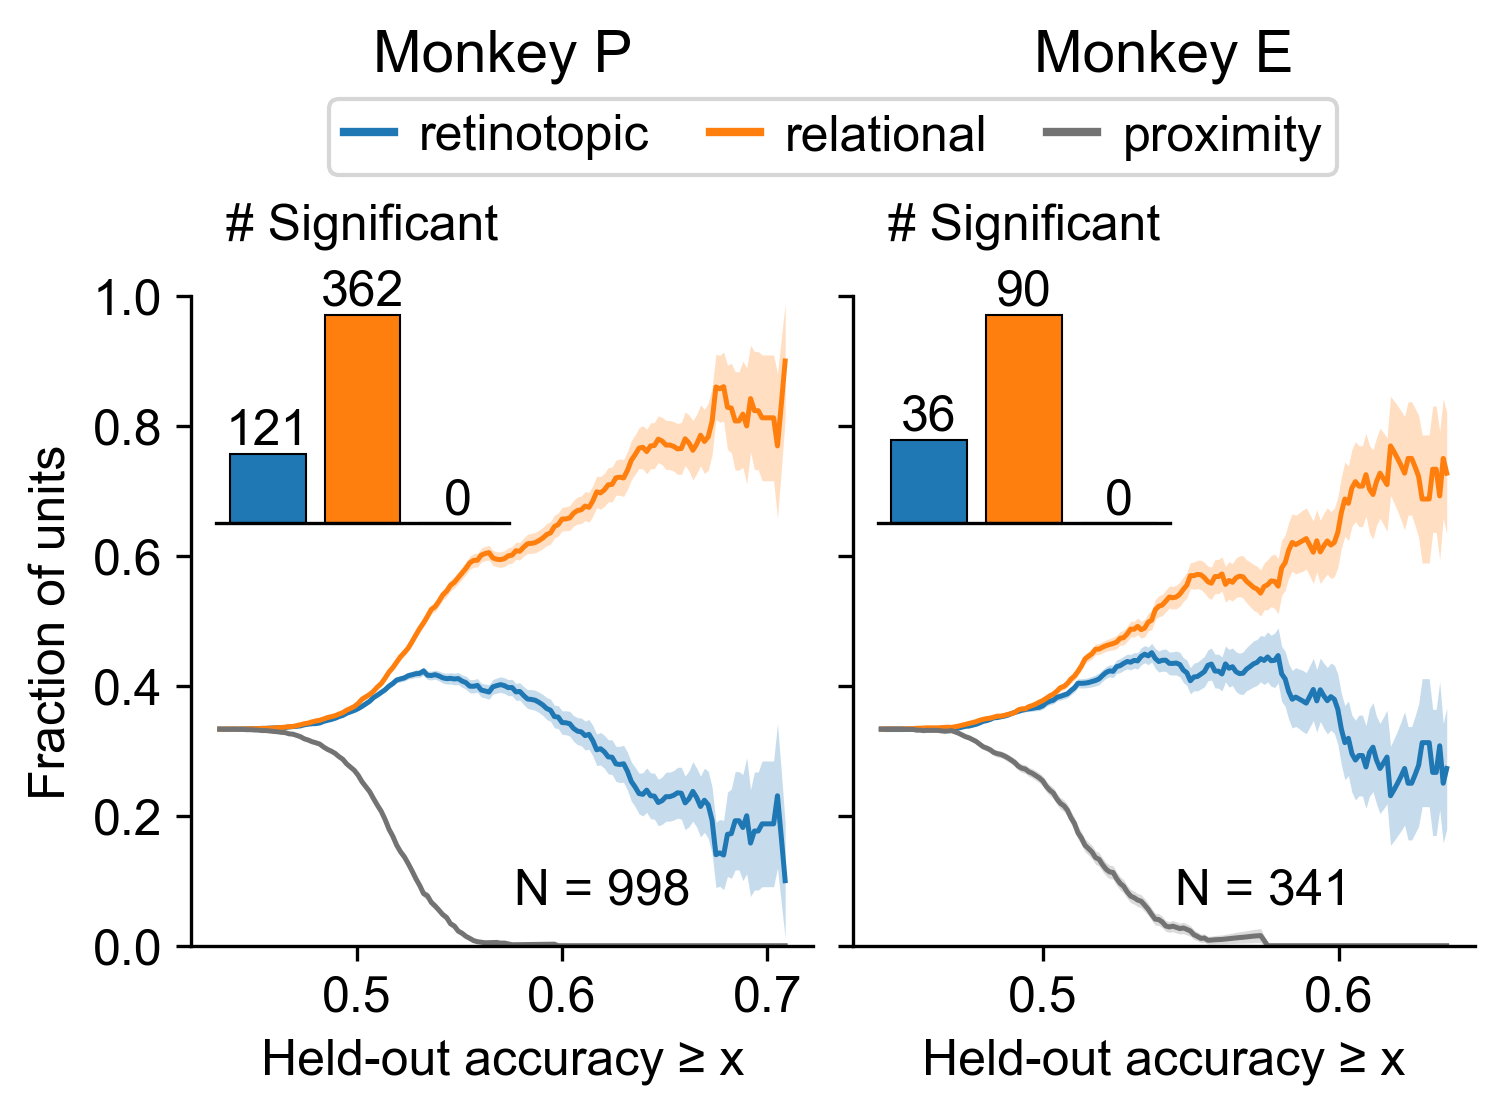

P(model wins) — mean over neurons, per model:
  Monkey P: retinotopic 0.348  relational 0.627  proximity 0.025   | winner pinned above 0.95 in 55% of neurons
  Monkey E: retinotopic 0.404  relational 0.557  proximity 0.039   | winner pinned above 0.95 in 43% of neurons

grand mean over models = 0.3333  (1/3 by construction)


In [3]:
fig = cl.plot_tail_with_count_insets(
    units, figsize=FIGSIZE, tail_kw=TAIL_KW,
    inset_bounds=(INSET_X0, INSET_Y0, INSET_WIDTH, INSET_HEIGHT),
    inset_headroom=INSET_HEADROOM, inset_title=INSET_TITLE,
    inset_title_pad=INSET_TITLE_PAD, n_xy=N_XY, title_pad=TITLE_PAD,
    legend_dy_in=LEGEND_DY_IN,
    legend_lw=LEGEND_LW)
common.save(fig, OUTPUT)
plt.show()

wf = [f'{m}_win_frac' for m in cl.MODELS]
print('P(model wins) — mean over neurons, per model:')
for s_ in sl.ordered_subjects(units):
    g = units[units['subject'] == s_]
    means = {m: g[f'{m}_win_frac'].mean() for m in cl.MODELS}
    stable = (g[wf].max(axis=1) > 0.95).mean()
    print(f'  {sl.subject_title(s_)}: ' + '  '.join(f'{m} {v:.3f}' for m, v in means.items())
          + f'   | winner pinned above 0.95 in {100 * stable:.0f}% of neurons')
print(f'\ngrand mean over models = {units[wf].to_numpy().mean():.4f}  (1/3 by construction)')

## 3. Which model is right, where they disagree

The sharpest form of the question. On a comparison where two models predict *different*
orderings, exactly one of them is right, so the weighted fraction the first one gets right is a
complete summary and 1/2 is the null of "equally good". This discards precisely the comparisons
that carry no discriminating information, and it cannot be moved by the two models having
differently shaped score differences.

`p` comes from resampling **trials**, which is the only honest unit here. `p_binom` is the exact
sign test over comparisons, reported beside it as a check — and the gap between the two is worth
looking at, because comparisons within a neuron are massively dependent and the binomial treats
them as independent.

In [4]:
rows = []
for (a, b) in cl._PAIR_NAMES:
    for s in sl.ordered_subjects(units):
        g = units[units['subject'] == s]
        rows.append(dict(
            subject=sl.subject_title(s), pair=f'{a} vs {b}',
            median_n=g[f'{a}_vs_{b}_n'].median(),
            median_prop_a=g[f'{a}_vs_{b}_prop_a'].median(),
            frac_a_favoured=(g[f'{a}_vs_{b}_prop_a'] > cl.CHANCE).mean(),
            frac_sig=(g[f'{a}_vs_{b}_p'] < DECISIVE_Q).mean(),
            frac_sig_binom=(g[f'{a}_vs_{b}_p_binom'] < DECISIVE_Q).mean()))
display(pd.DataFrame(rows).round(3))

,subject,pair,median_n,median_prop_a,frac_a_favoured,frac_sig,frac_sig_binom
0,Monkey P,retinotopic vs relational,38373.0,0.482,0.357,0.538,0.915
1,Monkey E,retinotopic vs relational,52755.0,0.493,0.413,0.416,0.886
2,Monkey P,retinotopic vs proximity,37720.0,0.542,0.867,0.585,0.925
3,Monkey E,retinotopic vs proximity,52994.0,0.536,0.877,0.519,0.935
4,Monkey P,relational vs proximity,37638.0,0.560,0.928,0.738,0.975
5,Monkey E,relational vs proximity,52025.0,0.545,0.915,0.616,0.938
